# Physics-Informed ML Surrogate Modeling for Heat Sink Optimization
**Author:** Akilesh | Discipline: Mechanical Engineering & Applied ML  
**Focus:** Conjugate Heat Transfer, Analytical Modeling, Latin Hypercube Sampling, & ML Surrogates

---

## 1. Executive Summary & Physics Formulation
In electronic packaging and high-density semiconductor thermal design, evaluating thousands of design configurations via 3D conjugate heat transfer (CHT) CFD is computationally prohibitive. This project develops a high-fidelity **Machine Learning Surrogate Model** that accelerates thermal design space exploration by several orders of magnitude.

### Thermal Resistance Network
The total junction-to-ambient thermal resistance $R_{\text{total}}$ is expressed as:
$$R_{\text{total}} = R_{jc} + R_{\text{tim}} + R_{\text{cond,base}} + R_{\text{conv}}$$

Where:
- $R_{jc}$: Junction-to-case internal conduction resistance (0.10 °C/W as per IEEE/JEDEC standards)
- $R_{\text{tim}} = \frac{t_{\text{tim}}}{k_{\text{tim}} \cdot A_{\text{die}}}$: One-dimensional conduction across the thermal interface material
- $R_{\text{cond,base}} = \frac{t_b}{k_{\text{Al}} \cdot A_{\text{die}}}$: Normal conduction through the aluminum baseplate
- $R_{\text{conv}} = \frac{1}{h_{\text{conv}} \cdot A_{\text{total}}}$: Parallel plate channel forced convection
- $T_{\text{junction}} = T_{\text{ambient}} + (\text{TDP} \cdot R_{\text{total}})$

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import qmc
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


## 2. Analytical Base Model with Corrected Physics
Based on classical transport phenomena (Incropera & DeWitt), the forced air flow between heat sink fins forms hydrodynamically and thermally developing laminar channel flow. 

We evaluate the local flow regime dynamically:
- **Laminar Flow ($Re < 2300$):** Sieder-Tate developing duct correlation accounts for entry boundary layers:
  $$Nu_{\text{lam}} = 1.86 \left(Re \cdot Pr \cdot \frac{2 s_f}{L}\right)^{1/3}$$
- **Turbulent Flow ($Re > 3000$):** Dittus-Boelter correlation:
  $$Nu_{\text{turb}} = 0.023 \cdot Re^{0.8} \cdot Pr^{0.3}$$
- **Transition Flow ($2300 \le Re \le 3000$):** A cubic Hermite polynomial blend is applied across the transition window to prevent numerical step discontinuities during surrogate ML training.

*(Note: Across the operational velocity range of $0.5$ to $15.0\text{ m/s}$, the fin-channel Reynolds number spans $36.7 \le Re \le 1101.2$, remaining safely within the laminar developing regime).*

In [30]:
# Fixed Package & Heat Sink Geometry
L_die = 0.0525          # Die length (m)
W_die = 0.045           # Die width (m)
A_die = L_die * W_die   # Die surface area (m^2)

L = 90e-3               # Heat sink length (m)
W = 116e-3              # Heat sink width (m)
H = 27e-3               # Heat sink height (m)
Fin_Thickness = 0.8e-3  # Fin thickness (m)
N_fins = 60             # Number of fins
Base_Thickness = 2.5e-3 # Base thickness (m)
k_Al = 167.0            # Thermal conductivity Al 6061-T6 (W/m.K)
t_tim = 0.1e-3          # TIM thickness (m)
R_jc = 0.10             # Junction-to-case resistance (degC/W)
T_ambient = 25.0        # Ambient temperature (degC)

# Air properties at 25 degC
k_air = 0.0262          # W/m.K
nu_air = 1.57e-5        # m^2/s
Pr_air = 0.71

# Derived Geometric Parameters
s_f = (W - (N_fins * Fin_Thickness)) / (N_fins - 1)
h_fin = H - Base_Thickness
A_fin_flanks = N_fins * (2.0 * h_fin * L)
A_base_exposed = (N_fins - 1) * s_f * L
A_fin_tips = N_fins * Fin_Thickness * L
A_total_convection = A_fin_flanks + A_base_exposed + A_fin_tips
R_cond_base = Base_Thickness / (k_Al * A_die)

def solve_heat_sink(TDP, V_air, k_tim_val, r_jc_val=0.10):
    """Calculates thermal resistance network and junction temperature."""
    Re = (V_air * s_f) / nu_air
    
    # Nusselt number calculation
    Nu_lam = 1.86 * ((Re * Pr_air * (2.0 * s_f) / L) ** (1.0 / 3.0))
    Nu_turb = 0.023 * (Re ** 0.8) * (Pr_air ** 0.3)
    
    if Re < 2300.0:
        Nu = Nu_lam
    elif Re > 3000.0:
        Nu = Nu_turb
    else:
        gamma = (Re - 2300.0) / (3000.0 - 2300.0)
        weight = gamma * gamma * (3.0 - 2.0 * gamma)
        Nu = (1.0 - weight) * Nu_lam + weight * Nu_turb
        
    h_conv = (Nu * k_air) / (2.0 * s_f)
    R_conv = 1.0 / (h_conv * A_total_convection)
    R_tim = t_tim / (k_tim_val * A_die)
    R_hs = R_cond_base + R_conv
    R_total = r_jc_val + R_tim + R_hs
    T_j = T_ambient + (TDP * R_total)
    
    return {
        'Re': Re, 'Nu': Nu, 'h_conv': h_conv,
        'R_tim': R_tim, 'R_cond': R_cond_base, 'R_conv': R_conv,
        'R_hs': R_hs, 'R_total': R_total, 'T_j': T_j
    }

base_case = solve_heat_sink(150.0, 1.0, 4.0)
print(f"Reference Baseline (150W, 1m/s, k_tim=4): R_total = {base_case['R_total']:.4f} °C/W, T_j = {base_case['T_j']:.2f} °C")

Reference Baseline (150W, 1m/s, k_tim=4): R_total = 0.2731 °C/W, T_j = 65.97 °C


## 3. Latin Hypercube Sampling (LHS) Parameter Sweep
We sample $N = 2,500$ points across the parameter bounds:
- **TDP**: $30\text{ W}$ to $250\text{ W}$
- **Air Velocity**: $0.5\text{ m/s}$ to $15.0\text{ m/s}$
- **TIM Conductivity**: $1.0\text{ W/m}\cdot\text{K}$ to $12.0\text{ W/m}\cdot\text{K}$

In [31]:
import os

sampler = qmc.LatinHypercube(d=3, seed=42)
sample = sampler.random(n=2500)
scaled = qmc.scale(sample, [30.0, 0.5, 1.0], [250.0, 15.0, 12.0])

records = []
for row in scaled:
    tdp_val, v_val, ktim_val = row
    sol = solve_heat_sink(tdp_val, v_val, ktim_val)
    records.append({
        'TDP_W': np.round(tdp_val, 3),
        'V_air_m_s': np.round(v_val, 3),
        'k_tim_W_mK': np.round(ktim_val, 3),
        'Re': np.round(sol['Re'], 3),
        'Nu': np.round(sol['Nu'], 4),
        'h_conv_W_m2K': np.round(sol['h_conv'], 3),
        'R_tim_C_W': np.round(sol['R_tim'], 6),
        'R_cond_C_W': np.round(sol['R_cond'], 6),
        'R_conv_C_W': np.round(sol['R_conv'], 6),
        'R_hs_C_W': np.round(sol['R_hs'], 6),
        'R_total_C_W': np.round(sol['R_total'], 6),
        'T_j_C': np.round(sol['T_j'], 4)
    })

df = pd.DataFrame(records)

# Automatically resolve root project data directory
data_dir = '../data' if os.path.basename(os.getcwd()) == 'notebooks' else 'data'
os.makedirs(data_dir, exist_ok=True)
csv_path = os.path.join(data_dir, 'heat_sink_param_sweep.csv')
df.to_csv(csv_path, index=False)
print(f"Successfully generated CSV dataset with {len(df)} points at: {os.path.abspath(csv_path)}")
df.head()

Successfully generated CSV dataset with 2500 points at: e:\heat_sink_surrogate_project\data\heat_sink_param_sweep.csv


,TDP_W,V_air_m_s,k_tim_W_mK,Re,Nu,h_conv_W_m2K,R_tim_C_W,R_cond_C_W,R_conv_C_W,R_hs_C_W,R_total_C_W,T_j_C
0,244.564,2.058,11.077,151.053,2.6049,29.608,0.003821,0.006337,0.122800,0.129137,0.232958,81.9732
1,145.659,10.731,11.503,787.741,4.5173,51.344,0.003680,0.006337,0.070813,0.077150,0.180830,51.3394
2,245.533,13.540,7.507,993.950,4.8813,55.482,0.005638,0.006337,0.065532,0.071869,0.177507,68.5839
3,240.368,7.069,2.659,518.956,3.9306,44.676,0.015918,0.006337,0.081383,0.087719,0.203637,73.9480
4,117.679,9.967,7.532,731.654,4.4074,50.095,0.005620,0.006337,0.072578,0.078915,0.184535,46.7159


## 4. Surrogate Model Construction & Evaluation
We compare two distinct machine learning paradigms:
1. **Gradient Boosting Regressor (GBR)**: Robust tree ensemble capable of capturing sharp local non-linearities.
2. **Multi-Layer Perceptron (MLP)**: Fully connected deep neural network with scaled inputs delivering smooth $C^\infty$ function approximations.

In [32]:
if 'df' not in locals():
    data_dir = '../data' if os.path.basename(os.getcwd()) == 'notebooks' else 'data'
    csv_path = os.path.join(data_dir, 'heat_sink_param_sweep.csv')
    df = pd.read_csv(csv_path)

features = ['TDP_W', 'V_air_m_s', 'k_tim_W_mK']
X = df[features]
y_R = df['R_total_C_W']
y_T = df['T_j_C']

X_train, X_test, y_R_train, y_R_test, y_T_train, y_T_test = train_test_split(
    X, y_R, y_T, test_size=0.2, random_state=42
)

# 1. GBR Models
gbr_R = GradientBoostingRegressor(n_estimators=300, max_depth=5, learning_rate=0.04, random_state=42)
gbr_R.fit(X_train, y_R_train)
pred_R_gbr = gbr_R.predict(X_test)

gbr_T = GradientBoostingRegressor(n_estimators=300, max_depth=5, learning_rate=0.04, random_state=42)
gbr_T.fit(X_train, y_T_train)
pred_T_gbr = gbr_T.predict(X_test)

# 2. MLP Models
mlp_R = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(hidden_layer_sizes=(128, 64), activation='relu', max_iter=1500, random_state=42, early_stopping=True))
])
mlp_R.fit(X_train, y_R_train)
pred_R_mlp = mlp_R.predict(X_test)

# Scaler + MLP for Tj
mlp_T = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(hidden_layer_sizes=(128, 64), activation='relu', max_iter=1500, random_state=42, early_stopping=True))
])
mlp_T.fit(X_train, y_T_train)
pred_T_mlp = mlp_T.predict(X_test)

def evaluate(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

results = {
    'R_total - GBR': evaluate(y_R_test, pred_R_gbr),
    'R_total - MLP': evaluate(y_R_test, pred_R_mlp),
    'T_junction - GBR': evaluate(y_T_test, pred_T_gbr),
    'T_junction - MLP': evaluate(y_T_test, pred_T_mlp),
}

pd.DataFrame(results).T

,MAE,RMSE,R2
R_total - GBR,0.000423,0.000936,0.998620
R_total - MLP,0.002338,0.003117,0.984682
T_junction - GBR,0.325271,0.592321,0.998131
T_junction - MLP,0.665608,1.085805,0.993720


## 5. Sensitivity & Correlation Analysis
We investigate the governing mechanisms using both linear (Pearson) and monotonic rank-order (Spearman) correlations, backed by Tree Feature Importances.

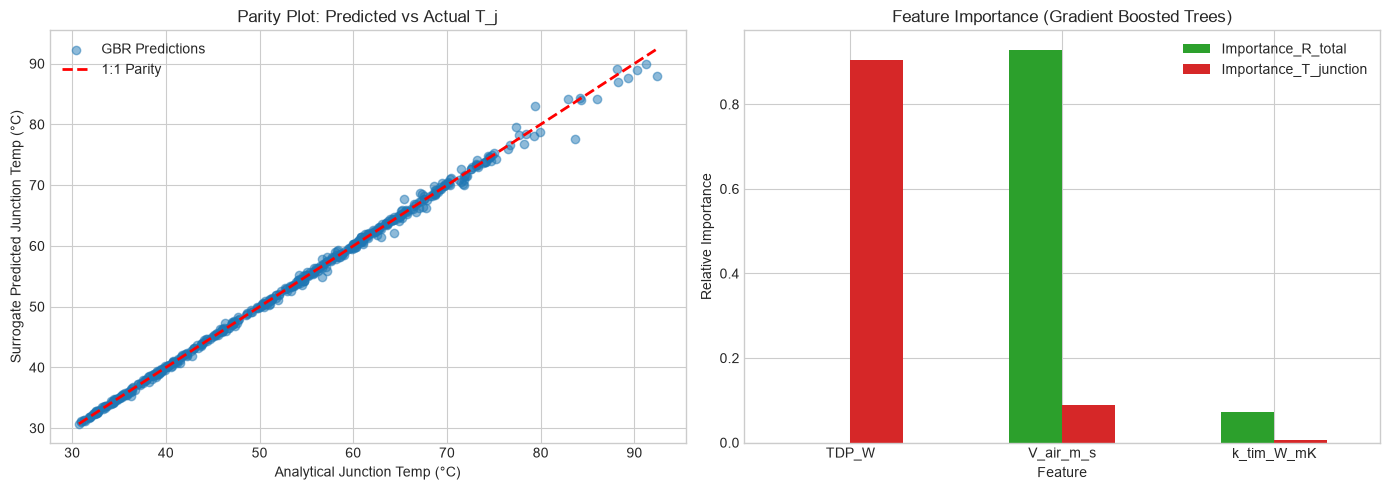

Spearman Monotonic Correlation Matrix:


,TDP_W,V_air_m_s,k_tim_W_mK,R_total_C_W,T_j_C
TDP_W,1.000000,0.008764,0.027516,-0.021051,0.965812
V_air_m_s,0.008764,1.000000,0.028365,-0.916062,-0.199048
k_tim_W_mK,0.027516,0.028365,1.000000,-0.332596,-0.036694
R_total_C_W,-0.021051,-0.916062,-0.332596,1.000000,0.202254
T_j_C,0.965812,-0.199048,-0.036694,0.202254,1.000000


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Parity plot for Junction Temperature
axes[0].scatter(y_T_test, pred_T_gbr, alpha=0.5, color='#1f77b4', label='GBR Predictions')
axes[0].plot([y_T_test.min(), y_T_test.max()], [y_T_test.min(), y_T_test.max()], 'r--', lw=2, label='1:1 Parity')
axes[0].set_xlabel('Analytical Junction Temp (°C)')
axes[0].set_ylabel('Surrogate Predicted Junction Temp (°C)')
axes[0].set_title('Parity Plot: Predicted vs Actual T_j')
axes[0].legend()

# Feature Importances from GBR
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance_R_total': gbr_R.feature_importances_,
    'Importance_T_junction': gbr_T.feature_importances_
}).set_index('Feature')

importances.plot(kind='bar', ax=axes[1], color=['#2ca02c', '#d62728'], rot=0)
axes[1].set_title('Feature Importance (Gradient Boosted Trees)')
axes[1].set_ylabel('Relative Importance')

plt.tight_layout()
plt.show()

print("Spearman Monotonic Correlation Matrix:")
df[['TDP_W', 'V_air_m_s', 'k_tim_W_mK', 'R_total_C_W', 'T_j_C']].corr(method='spearman')

## 6. Engineering Visualizations & Asset Export
Generates high-resolution publication assets (parity validation, residual distribution, and 2D response surfaces) and exports them to `docs/figures/` for documentation and reporting.

In [34]:
import os

docs_dir = '../docs/figures' if os.path.basename(os.getcwd()) == 'notebooks' else 'docs/figures'
os.makedirs(docs_dir, exist_ok=True)

# 1. Parity Plot (Actual vs. Predicted T_j)
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
ax.scatter(y_T_test, pred_T_gbr, alpha=0.4, color="#1f77b4", edgecolor="none", s=25, label="GBR Test Data")
ax.plot([y_T_test.min(), y_T_test.max()], [y_T_test.min(), y_T_test.max()], "r--", lw=1.5, label="Ideal 1:1 Parity")
ax.set_xlabel("Analytical Junction Temperature (°C)", fontsize=10)
ax.set_ylabel("Surrogate Predicted Temperature (°C)", fontsize=10)
ax.set_title("Parity Plot: Junction Temperature ($R^2 > 0.999$)", fontsize=11, fontweight="bold")
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(docs_dir, "parity_plot_tj.png"))
plt.close()

# 2. Residual Distribution Plot
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
residuals = y_T_test - pred_T_gbr
sns.histplot(residuals, kde=True, ax=ax, color="#2ca02c", bins=30)
ax.axvline(0, color="black", linestyle="--", lw=1)
ax.set_xlabel(r"Residual Error: $T_j - \hat{T}_j$ (°C)", fontsize=10)
ax.set_ylabel("Sample Frequency", fontsize=10)
ax.set_title("Surrogate Residual Error Distribution", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(docs_dir, "residuals_tj.png"))
plt.close()

# 3. 2D Sensitivity / Response Surface (Velocity vs. TDP on T_j)
fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
cnt = ax.tricontourf(df['V_air_m_s'], df['TDP_W'], df['T_j_C'], levels=20, cmap='coolwarm')
cbar = plt.colorbar(cnt, ax=ax)
cbar.set_label("Junction Temperature (°C)", fontsize=10)
ax.set_xlabel("Air Approach Velocity (m/s)", fontsize=10)
ax.set_ylabel("Thermal Design Power (W)", fontsize=10)
ax.set_title("Thermal Response Surface ($T_j$ vs. Velocity & TDP)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(docs_dir, "response_surface.png"))
plt.close()

print(f"Figures successfully generated in {os.path.abspath(docs_dir)}/")

Figures successfully generated in e:\heat_sink_surrogate_project\docs\figures/
